# Cross-species epilepsy: pathway transfer and functional organization

## Introduction

This study tests whether frozen BridgeRNA representations identify corresponding transcriptional programs between human mesial temporal lobe epilepsy (MTLE) and phase-specific mouse kainate epilepsy. The strict evaluation uses studies absent from Bridge pretraining, valid natural `log1p(TPM)` inputs, no fitted cross-species alignment, and matched raw-expression and PCA baselines.

The evaluation covers three endpoints: cross-species sample-direction alignment, zero-shot recovery of mouse pathway state by a human-trained Hallmark head, and functional organization of contextual gene networks. All displayed results are recomputed from compact frozen tables; no model inference is performed.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PACKAGE = Path.cwd()
if not (PACKAGE / 'data').exists():
    candidate = PACKAGE / 'benchmarks' / 'cross_species_epilepsy'
    if candidate.exists():
        PACKAGE = candidate
CACHE = PACKAGE / 'data'
FIGURES = PACKAGE / 'figures'
assert CACHE.exists() and FIGURES.exists()
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'pdf.fonttype': 42})
print(f'Cached evidence: {CACHE}')

Cached evidence: /home/walt/bridge-rna/benchmarks/cross_species_epilepsy/data


## Data and preprocessing

- Human GSE256068/PRJNA1077986: 58 MTLE cases and 10 controls, whole hippocampal tissue, predominantly MTLE with hippocampal sclerosis.
- Mouse GSE319769/PRJNA1425071: intra-amygdala kainate and matched vehicle/control, with 6 animals per condition at Day 3 (acute), Day 7 (intermediate), and Day 14 (chronic). Phases use independent animals.
- All 104 samples are study-unseen to Bridge pretraining.
- Human inputs use deposited NCBI TPM and cover 15,141/15,165 canonical ortholog genes; mouse TPM was calculated from HTSeq counts with Ensembl-112 exon-union lengths and covers all 15,165 genes.
- Bridge receives natural `log1p(TPM)` in canonical vocabulary order. No cross-species alignment or domain adaptation is fitted.

In [2]:
manifest = pd.read_csv(CACHE / 'primary_manifest.csv')
assert len(manifest) == 104
assert manifest['gsm'].nunique() == 104
cohort = manifest.groupby(['species', 'phenotype', 'phase'], dropna=False).size().rename('N').reset_index()
display(cohort)
print('Unique biological samples:', len(manifest))

,species,phenotype,phase,N
0,human,Mesial temporal lobe epilepsy,NaN,58
1,human,Normal control,NaN,10
2,mouse,Case,Acute,6
3,mouse,Case,Chronic,6
4,mouse,Case,Intermediate,6
5,mouse,Control,Acute,6
6,mouse,Control,Chronic,6
7,mouse,Control,Intermediate,6


Unique biological samples: 104


## Frozen sample representations and cross-species disease directions

For human samples, $\Delta_H=\mathrm{mean}(z_{MTLE})-\mathrm{mean}(z_{control})$. For each mouse phase, $\Delta_{M,k}=\mathrm{mean}(z_{kainate,k})-\mathrm{mean}(z_{vehicle,k})$. The primary statistic is cosine similarity. Uncertainty uses 5,000 biological-sample bootstraps; inference uses 10,000 within-study/phase phenotype-label permutations.

,mouse_phase,observed_cosine,bootstrap_ci_low,bootstrap_ci_high,permutation_p_one_sided,standardized_vs_null
0,Acute,0.5326,0.3885,0.6426,0.1888,1.0763
1,Intermediate,0.2753,0.1413,0.4270,0.2448,0.7850
2,Chronic,0.2356,-0.0518,0.5730,0.3063,0.6228


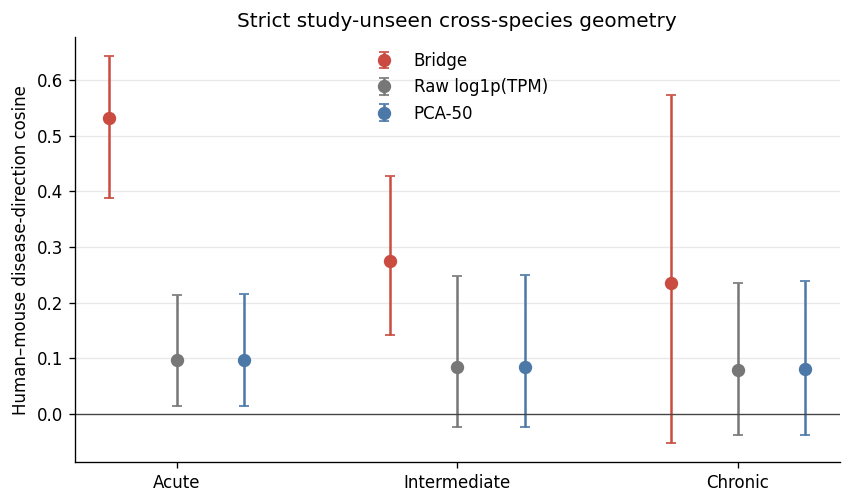

In [3]:
directions = pd.read_csv(CACHE / 'primary_direction_metrics.csv')
order = ['Acute', 'Intermediate', 'Chronic']
bridge = directions.query("method == 'Bridge'").set_index('mouse_phase').loc[order].reset_index()
expected = np.array([0.532620, 0.275335, 0.235620])
assert np.allclose(bridge['observed_cosine'], expected, atol=5e-7)
display(bridge[['mouse_phase','observed_cosine','bootstrap_ci_low','bootstrap_ci_high',
                'permutation_p_one_sided','standardized_vs_null']].round(4))

fig, ax = plt.subplots(figsize=(7.2, 4.3))
methods = ['Bridge', 'Raw log1p(TPM)', 'PCA-50']
colors = {'Bridge':'#ca4b3f','Raw log1p(TPM)':'#777777','PCA-50':'#4c78a8'}
x = np.arange(3); width = 0.24
for j, method in enumerate(methods):
    q = directions.query('method == @method').set_index('mouse_phase').loc[order]
    y = q['observed_cosine'].to_numpy()
    lo = y - q['bootstrap_ci_low'].to_numpy(); hi = q['bootstrap_ci_high'].to_numpy() - y
    ax.errorbar(x + (j-1)*width, y, yerr=np.vstack([lo,hi]), fmt='o', ms=7,
                color=colors[method], capsize=3, label=method)
ax.axhline(0, color='#444', lw=.8)
ax.set(xticks=x, xticklabels=order, ylabel='Human–mouse disease-direction cosine',
       title='Strict study-unseen cross-species geometry')
ax.legend(frameon=False); ax.grid(axis='y', color='#e8e8e8')
fig.tight_layout()
fig.savefig(FIGURES / 'primary_direction_comparison.png', dpi=300)
fig.savefig(FIGURES / 'primary_direction_comparison.pdf')
plt.show()

Bridge produced the largest acute point estimate (0.5326 versus approximately 0.0975 for raw expression and PCA), but no phase exceeded its own phenotype-label null. The positive bootstrap interval quantifies sampling stability conditional on the observed labels and does not supersede the permutation test.

## Zero-shot Hallmark recovery in mouse epilepsy

A frozen 512→50 Ridge head trained on human GTEx samples predicts ssGSEA-like Hallmark activity from Bridge sample embeddings. Applying it unchanged to mouse samples tests zero-shot functional-state transfer. Disease effects are kainate minus phase-matched control. Because the head was trained against expression-derived pathway targets, agreement with conventional GSEA is transfer/recovery evidence rather than an independent assay.

,pearson,spearman,same_sign_fraction
phase,,,
Acute,0.5819,0.6596,0.78
Intermediate,0.3759,0.3466,0.92
Chronic,0.4066,0.5673,0.86


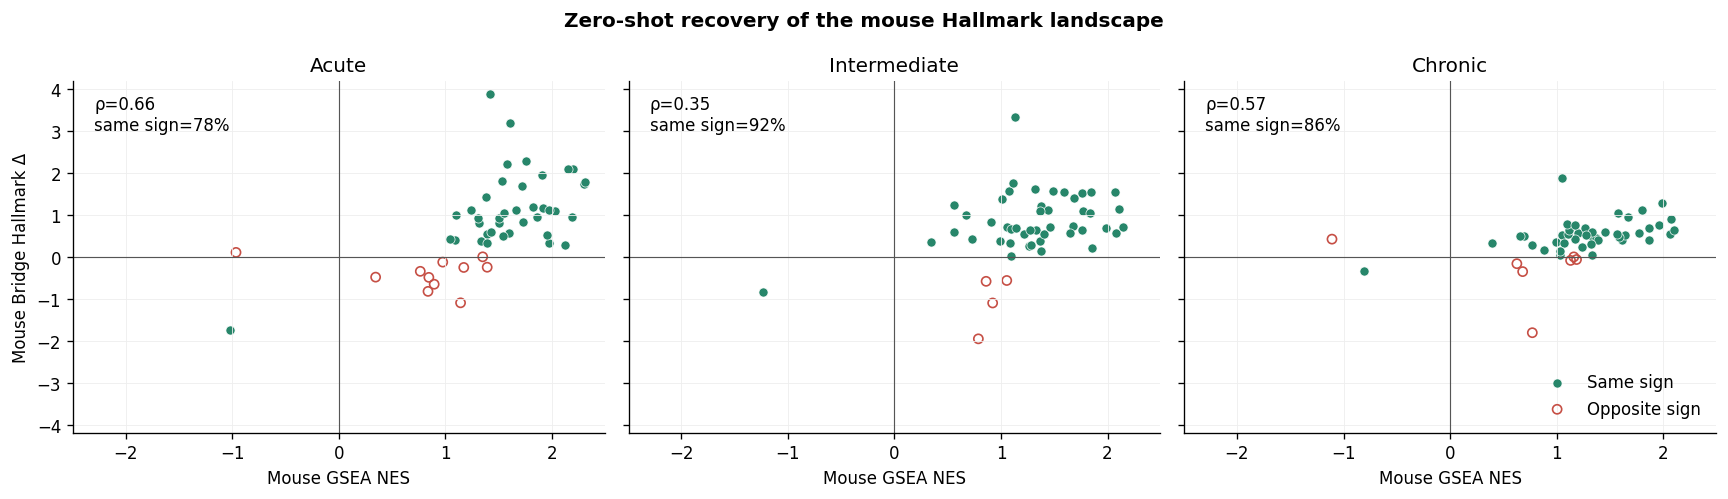

In [4]:
recovery = pd.read_csv(CACHE / 'mouse_hallmark_recovery_values.csv')
metrics = pd.read_csv(CACHE / 'mouse_hallmark_recovery_metrics.csv')
assert len(recovery) == 150
assert recovery.groupby('phase')['hallmark'].nunique().eq(50).all()
mouse = metrics.query("comparison == 'Mouse GSEA ↔ Bridge'").set_index('phase').loc[order]
display(mouse[['pearson','spearman','same_sign_fraction']].round(4))

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), sharex=True, sharey=True)
limx = 1.08 * recovery['mouse_gsea_nes'].abs().max()
limy = 1.08 * recovery['mouse_head_delta'].abs().max()
for ax, phase in zip(axes, order):
    q = recovery.query('phase == @phase')
    same = np.sign(q.mouse_gsea_nes) == np.sign(q.mouse_head_delta)
    ax.scatter(q.loc[same,'mouse_gsea_nes'], q.loc[same,'mouse_head_delta'], s=30,
               color='#27866a', edgecolor='white', lw=.4, label='Same sign')
    ax.scatter(q.loc[~same,'mouse_gsea_nes'], q.loc[~same,'mouse_head_delta'], s=30,
               facecolor='none', edgecolor='#c64f45', lw=1, label='Opposite sign')
    ax.axhline(0,color='#555',lw=.7); ax.axvline(0,color='#555',lw=.7)
    m = mouse.loc[phase]
    ax.text(.04,.96,f"ρ={m.spearman:.2f}\nsame sign={100*m.same_sign_fraction:.0f}%",
            transform=ax.transAxes,va='top')
    ax.set(title=phase, xlim=(-limx,limx), ylim=(-limy,limy), xlabel='Mouse GSEA NES')
    ax.grid(color='#eeeeee',lw=.5)
axes[0].set_ylabel('Mouse Bridge Hallmark Δ')
axes[-1].legend(frameon=False, loc='lower right')
fig.suptitle('Zero-shot recovery of the mouse Hallmark landscape', fontweight='bold')
fig.tight_layout()
fig.savefig(FIGURES / 'mouse_hallmark_recovery_scatter.png', dpi=300)
fig.savefig(FIGURES / 'mouse_hallmark_recovery_scatter.pdf')
plt.show()

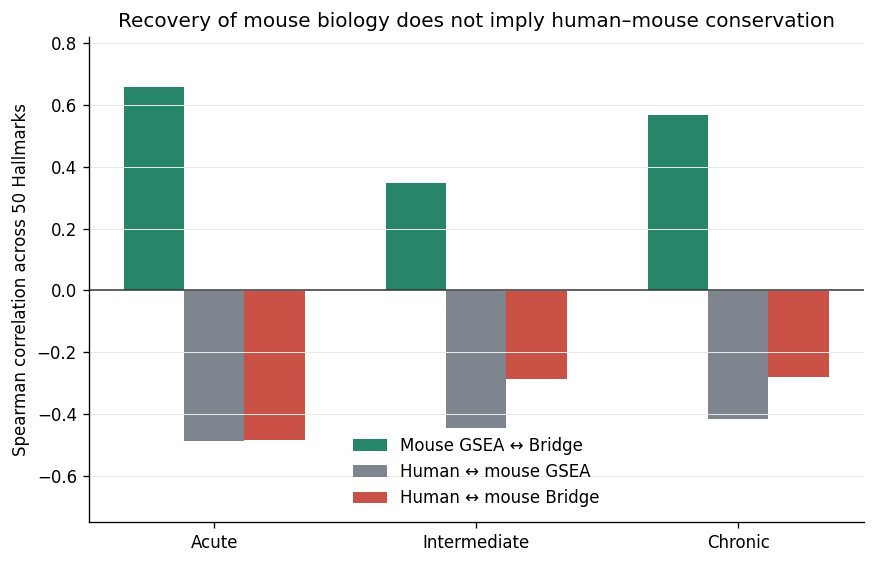

In [5]:
comparisons = ['Mouse GSEA ↔ Bridge', 'Human ↔ mouse GSEA', 'Human ↔ mouse Bridge']
colors = ['#27866a', '#7f858e', '#ca5145']
x = np.arange(3); width = 0.23
fig, ax = plt.subplots(figsize=(7.4, 4.8))
for i, (comparison, color) in enumerate(zip(comparisons, colors)):
    q = metrics.query('comparison == @comparison').set_index('phase').loc[order]
    ax.bar(x + (i-1)*width, q['spearman'], width, color=color, label=comparison)
ax.axhline(0, color='#333333', lw=.9)
ax.set(xticks=x, xticklabels=order, ylim=(-.75,.82),
       ylabel='Spearman correlation across 50 Hallmarks',
       title='Recovery of mouse biology does not imply human–mouse conservation')
ax.grid(axis='y', color='#e8e8e8', lw=.6)
ax.legend(frameon=False, loc='lower center')
fig.tight_layout()
fig.savefig(FIGURES / 'hallmark_recovery_vs_conservation.png', dpi=300)
fig.savefig(FIGURES / 'hallmark_recovery_vs_conservation.pdf')
plt.show()

Across all 50 Hallmarks, mouse GSEA versus mouse Bridge-head Spearman correlation was 0.6596 acute, 0.3466 intermediate, and 0.5673 chronic; sign agreement was 78%, 92%, and 86%. This demonstrates functional transfer to mouse without mouse retraining. The comparison panel makes the boundary explicit: both conventional GSEA and the Bridge head show negative human–mouse rank correlation in this strict cohort. Mouse functional recovery therefore does not establish global human–mouse conservation.

In [6]:
strict_head = pd.read_csv(CACHE / 'strict_hallmark_correspondence.csv')
head_cos = strict_head.query("statistic == 'cosine'").set_index('phase').loc[order]
display(head_cos[['observed','bootstrap_ci_low','bootstrap_ci_high',
                  'permutation_p_one_sided','family_q']].round(4))

,observed,bootstrap_ci_low,bootstrap_ci_high,permutation_p_one_sided,family_q
phase,,,,,
Acute,-0.4841,-0.6909,0.4004,0.8114,0.8697
Intermediate,-0.4198,-0.6624,0.4829,0.7298,0.8697
Chronic,-0.3498,-0.6151,0.5081,0.6778,0.8697


## Human pathway structure retained after compression

Conventional GSEA tests coordinated movement of pathway genes in the human MTLE differential-expression ranking, whereas the Hallmark head projects the mean-pooled 512-dimensional Bridge representation onto functional axes learned from GTEx. Their numerical scales are not interchangeable. The comparison below therefore scales each method by its across-pathway standard deviation without centering; zero and the original effect directions are preserved.

Same raw direction: 35/50 (70%)
Supported by both methods: 2/50
Opposite direction and supported by either method: 4/50


,hallmark,nes,fdr_q,human_delta,human_delta_ci_low,human_delta_ci_high,evidence_category
5,Apical Surface,-0.9743,0.9048,0.4648,0.2494,0.6743,Bridge only
7,Bile Acid Metabolism,-0.8399,1.0000,0.1505,0.0765,0.2235,Bridge only
10,Complement,-1.6603,0.0154,0.0442,-0.1294,0.2231,GSEA only
16,Fatty Acid Metabolism,-0.6432,1.0000,0.2362,0.0694,0.4470,Bridge only


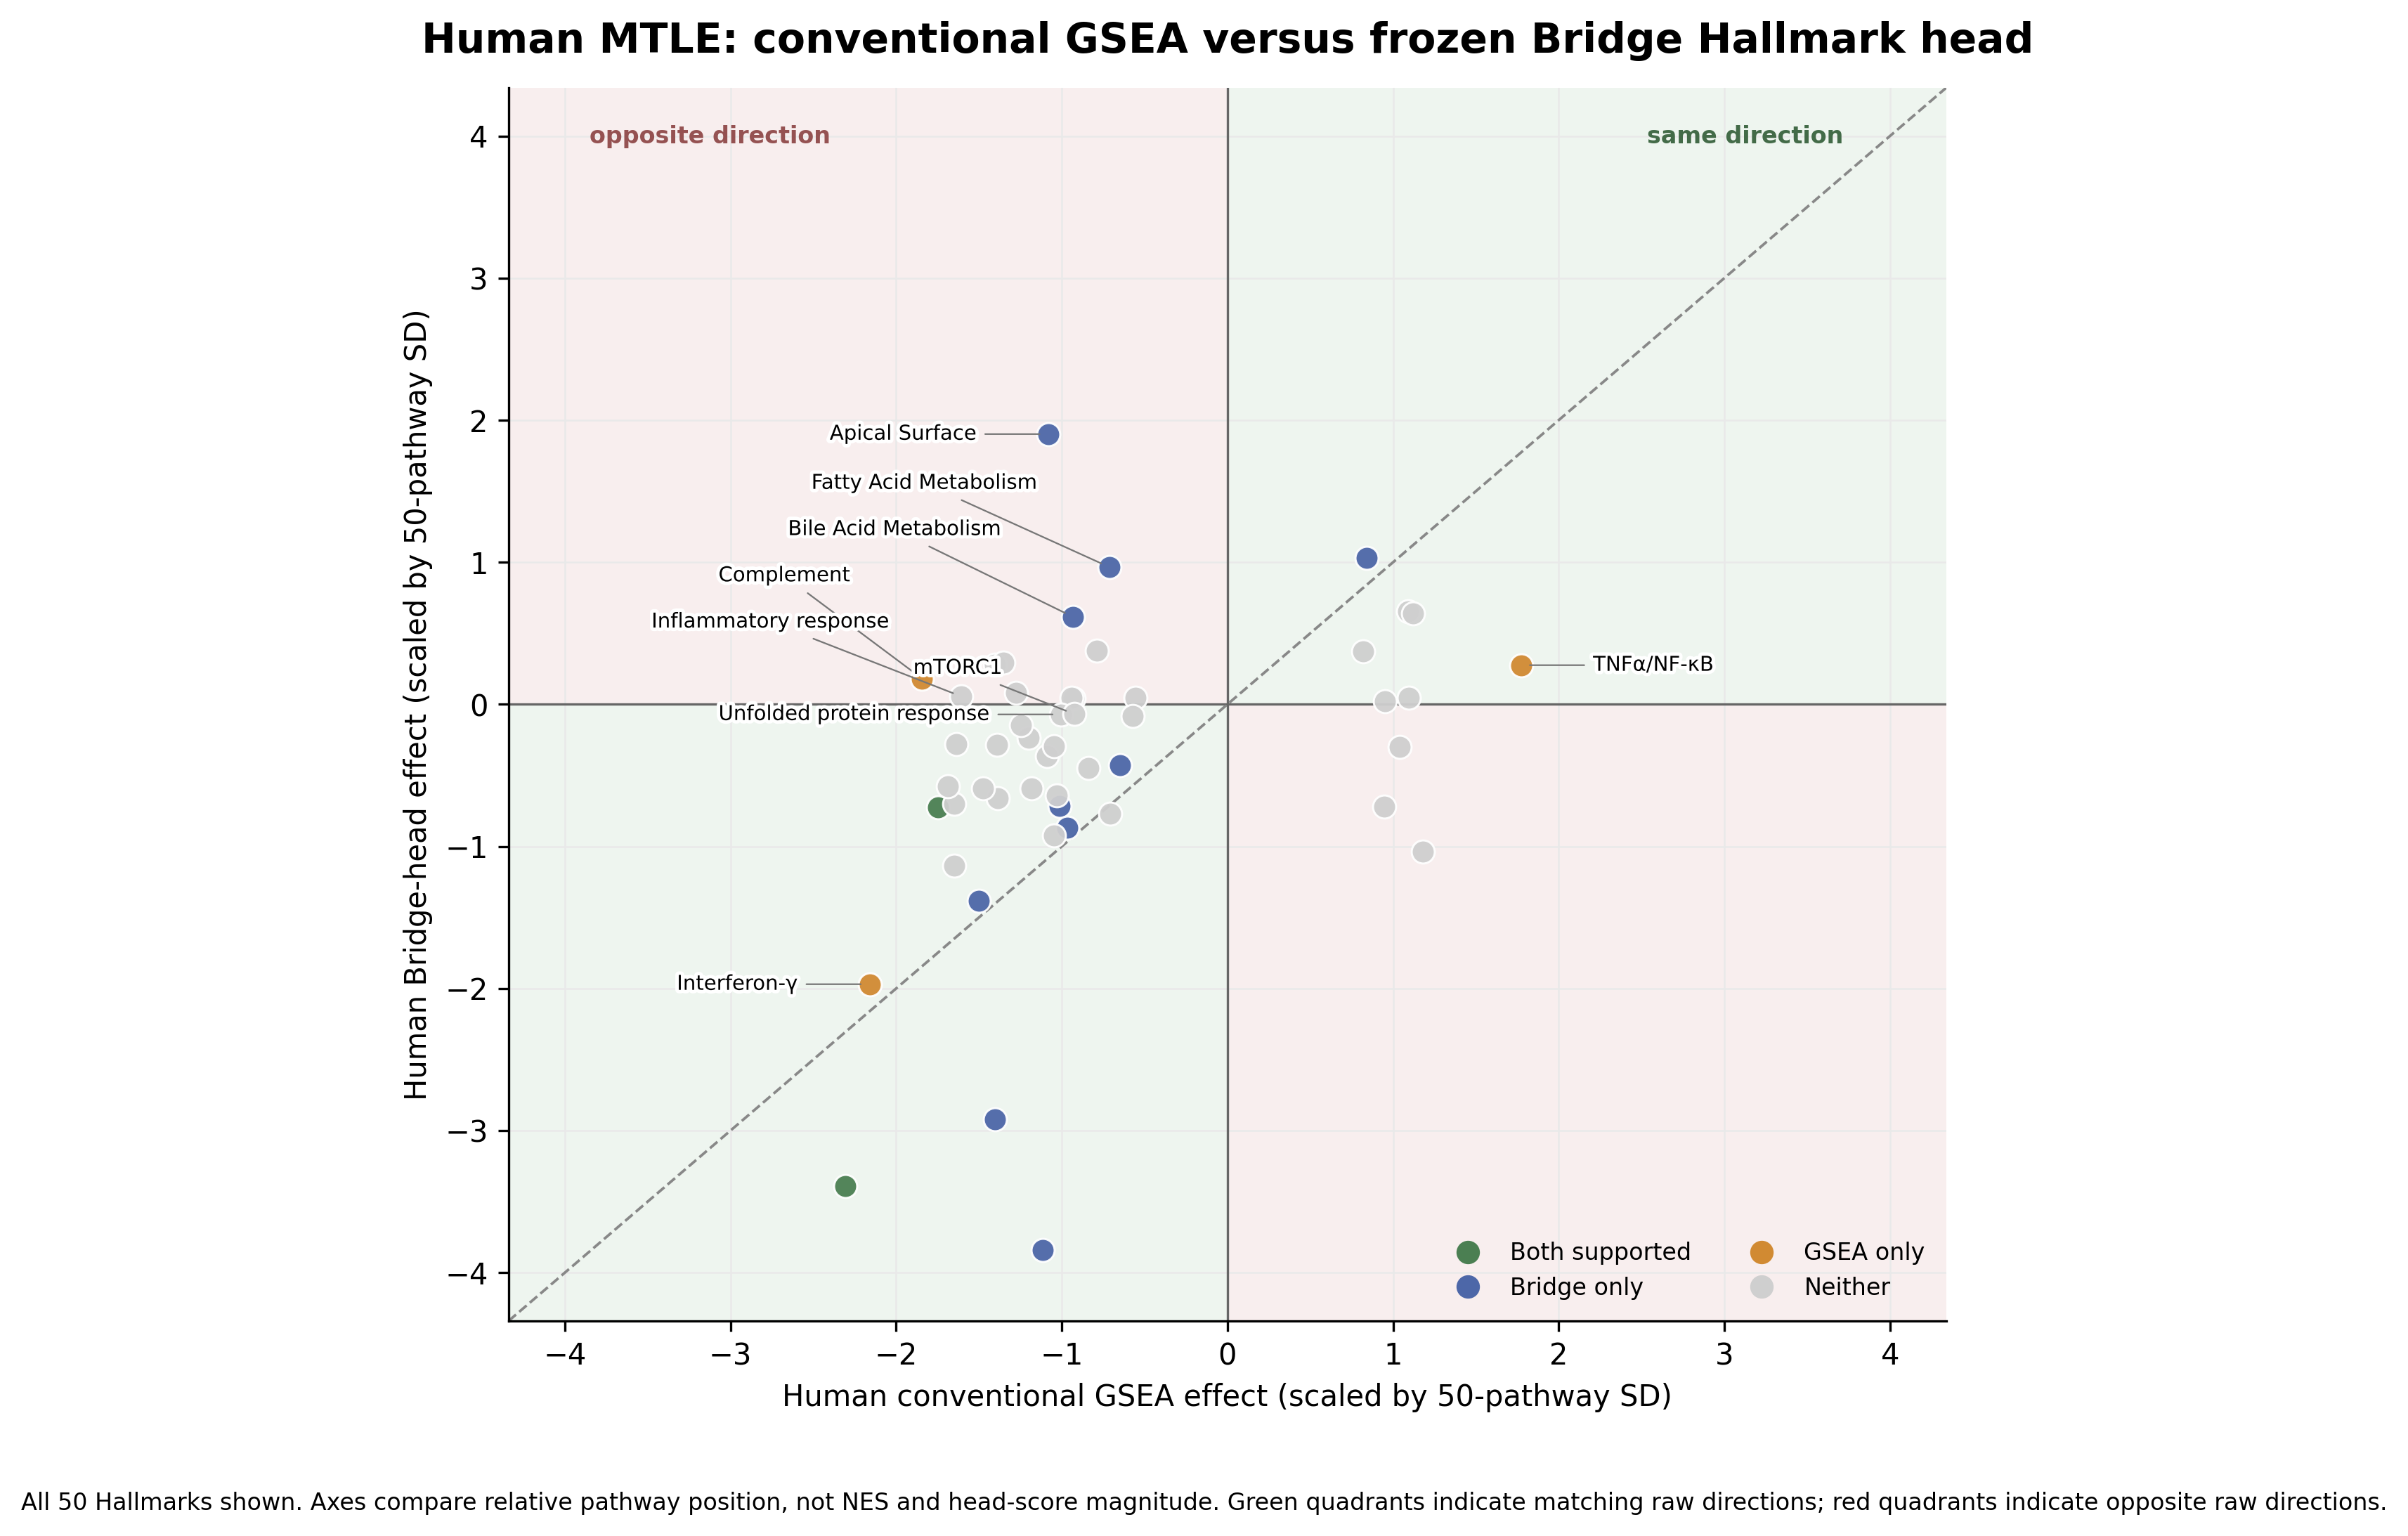

In [7]:
human_agreement = pd.read_csv(CACHE / 'human_bridge_gsea_agreement.csv')
assert len(human_agreement) == 50
same_direction = human_agreement['direction'].eq('same direction').sum()
both_supported = human_agreement['evidence_category'].eq('Both supported').sum()
supported_discordant = human_agreement['supported_discordant'].sum()
assert (same_direction, both_supported, supported_discordant) == (35, 2, 4)
print(f'Same raw direction: {same_direction}/50 ({100*same_direction/50:.0f}%)')
print(f'Supported by both methods: {both_supported}/50')
print(f'Opposite direction and supported by either method: {supported_discordant}/50')
display(human_agreement.loc[human_agreement.supported_discordant,
       ['hallmark','nes','fdr_q','human_delta','human_delta_ci_low',
        'human_delta_ci_high','evidence_category']].round(4))
display(Image(filename=str(FIGURES / 'human_bridge_gsea_agreement.png'), width=900))

Bridge retained the raw direction of 35/50 Hallmarks (70%) despite compression from 15,165 genes to a 512-dimensional sample representation and then to 50 functional scores. Angiogenesis and Interferon Alpha Response were supported in the same negative direction by both method-specific criteria, so directional agreement is broader than shared inferential support. Four supported discordances were resolved by one method only: Bridge-positive Apical Surface, Bile Acid Metabolism, and Fatty Acid Metabolism contrasted with nonsignificant negative GSEA tendencies, whereas GSEA supported negative Complement and Bridge was unresolved. The lipid-related Bridge results are compatible with known MTLE lipid remodeling, but the head score denotes a learned functional state rather than increased lipid abundance. Overall, the human result is best described as partial directional retention with attenuation and method-specific resolution, not full reproduction of the GSEA landscape.

## Phase-resolved injury, energy, and signaling programs

The focused pathway panel uses 22 prespecified epilepsy-relevant Hallmarks. Filled Bridge markers indicate biological-sample bootstrap intervals excluding zero; filled GSEA markers indicate BH q<0.05. These support criteria are not calibrated equivalents. Within each biological block, pathways are ordered by their observed Bridge phase swing, so the figure is descriptive rather than a confirmatory pathway ranking.

,biological_group,hallmark,bridge_acute,bridge_intermediate,bridge_chronic,gsea_acute,gsea_intermediate,gsea_chronic
0,Seizure injury / inflammation,Unfolded Protein Response,3.187,0.693,0.779,1.610,1.140,1.096
1,Seizure injury / inflammation,p53 Pathway,2.291,1.534,1.038,1.753,1.592,1.575
2,Seizure injury / inflammation,Interferon Alpha Response,1.735,0.707,0.637,2.301,2.144,2.102
3,Seizure injury / inflammation,Reactive Oxygen Species Pathway,1.421,1.624,0.596,1.377,1.317,1.333
4,Seizure injury / inflammation,Apoptosis,1.945,1.514,0.948,1.908,1.756,1.670
5,Seizure injury / inflammation,TNF-alpha Signaling via NF-kB,2.100,1.557,1.128,2.155,1.847,1.804
6,Seizure injury / inflammation,Interferon Gamma Response,1.775,1.133,0.909,2.311,2.106,2.071
7,Seizure injury / inflammation,IL-6/JAK/STAT3 Signaling,2.104,1.543,1.275,2.195,2.071,1.992
8,Seizure injury / inflammation,Inflammatory Response,0.955,0.693,0.754,2.191,1.987,1.958
9,Seizure injury / inflammation,Complement,0.529,0.638,0.577,1.953,1.761,1.774


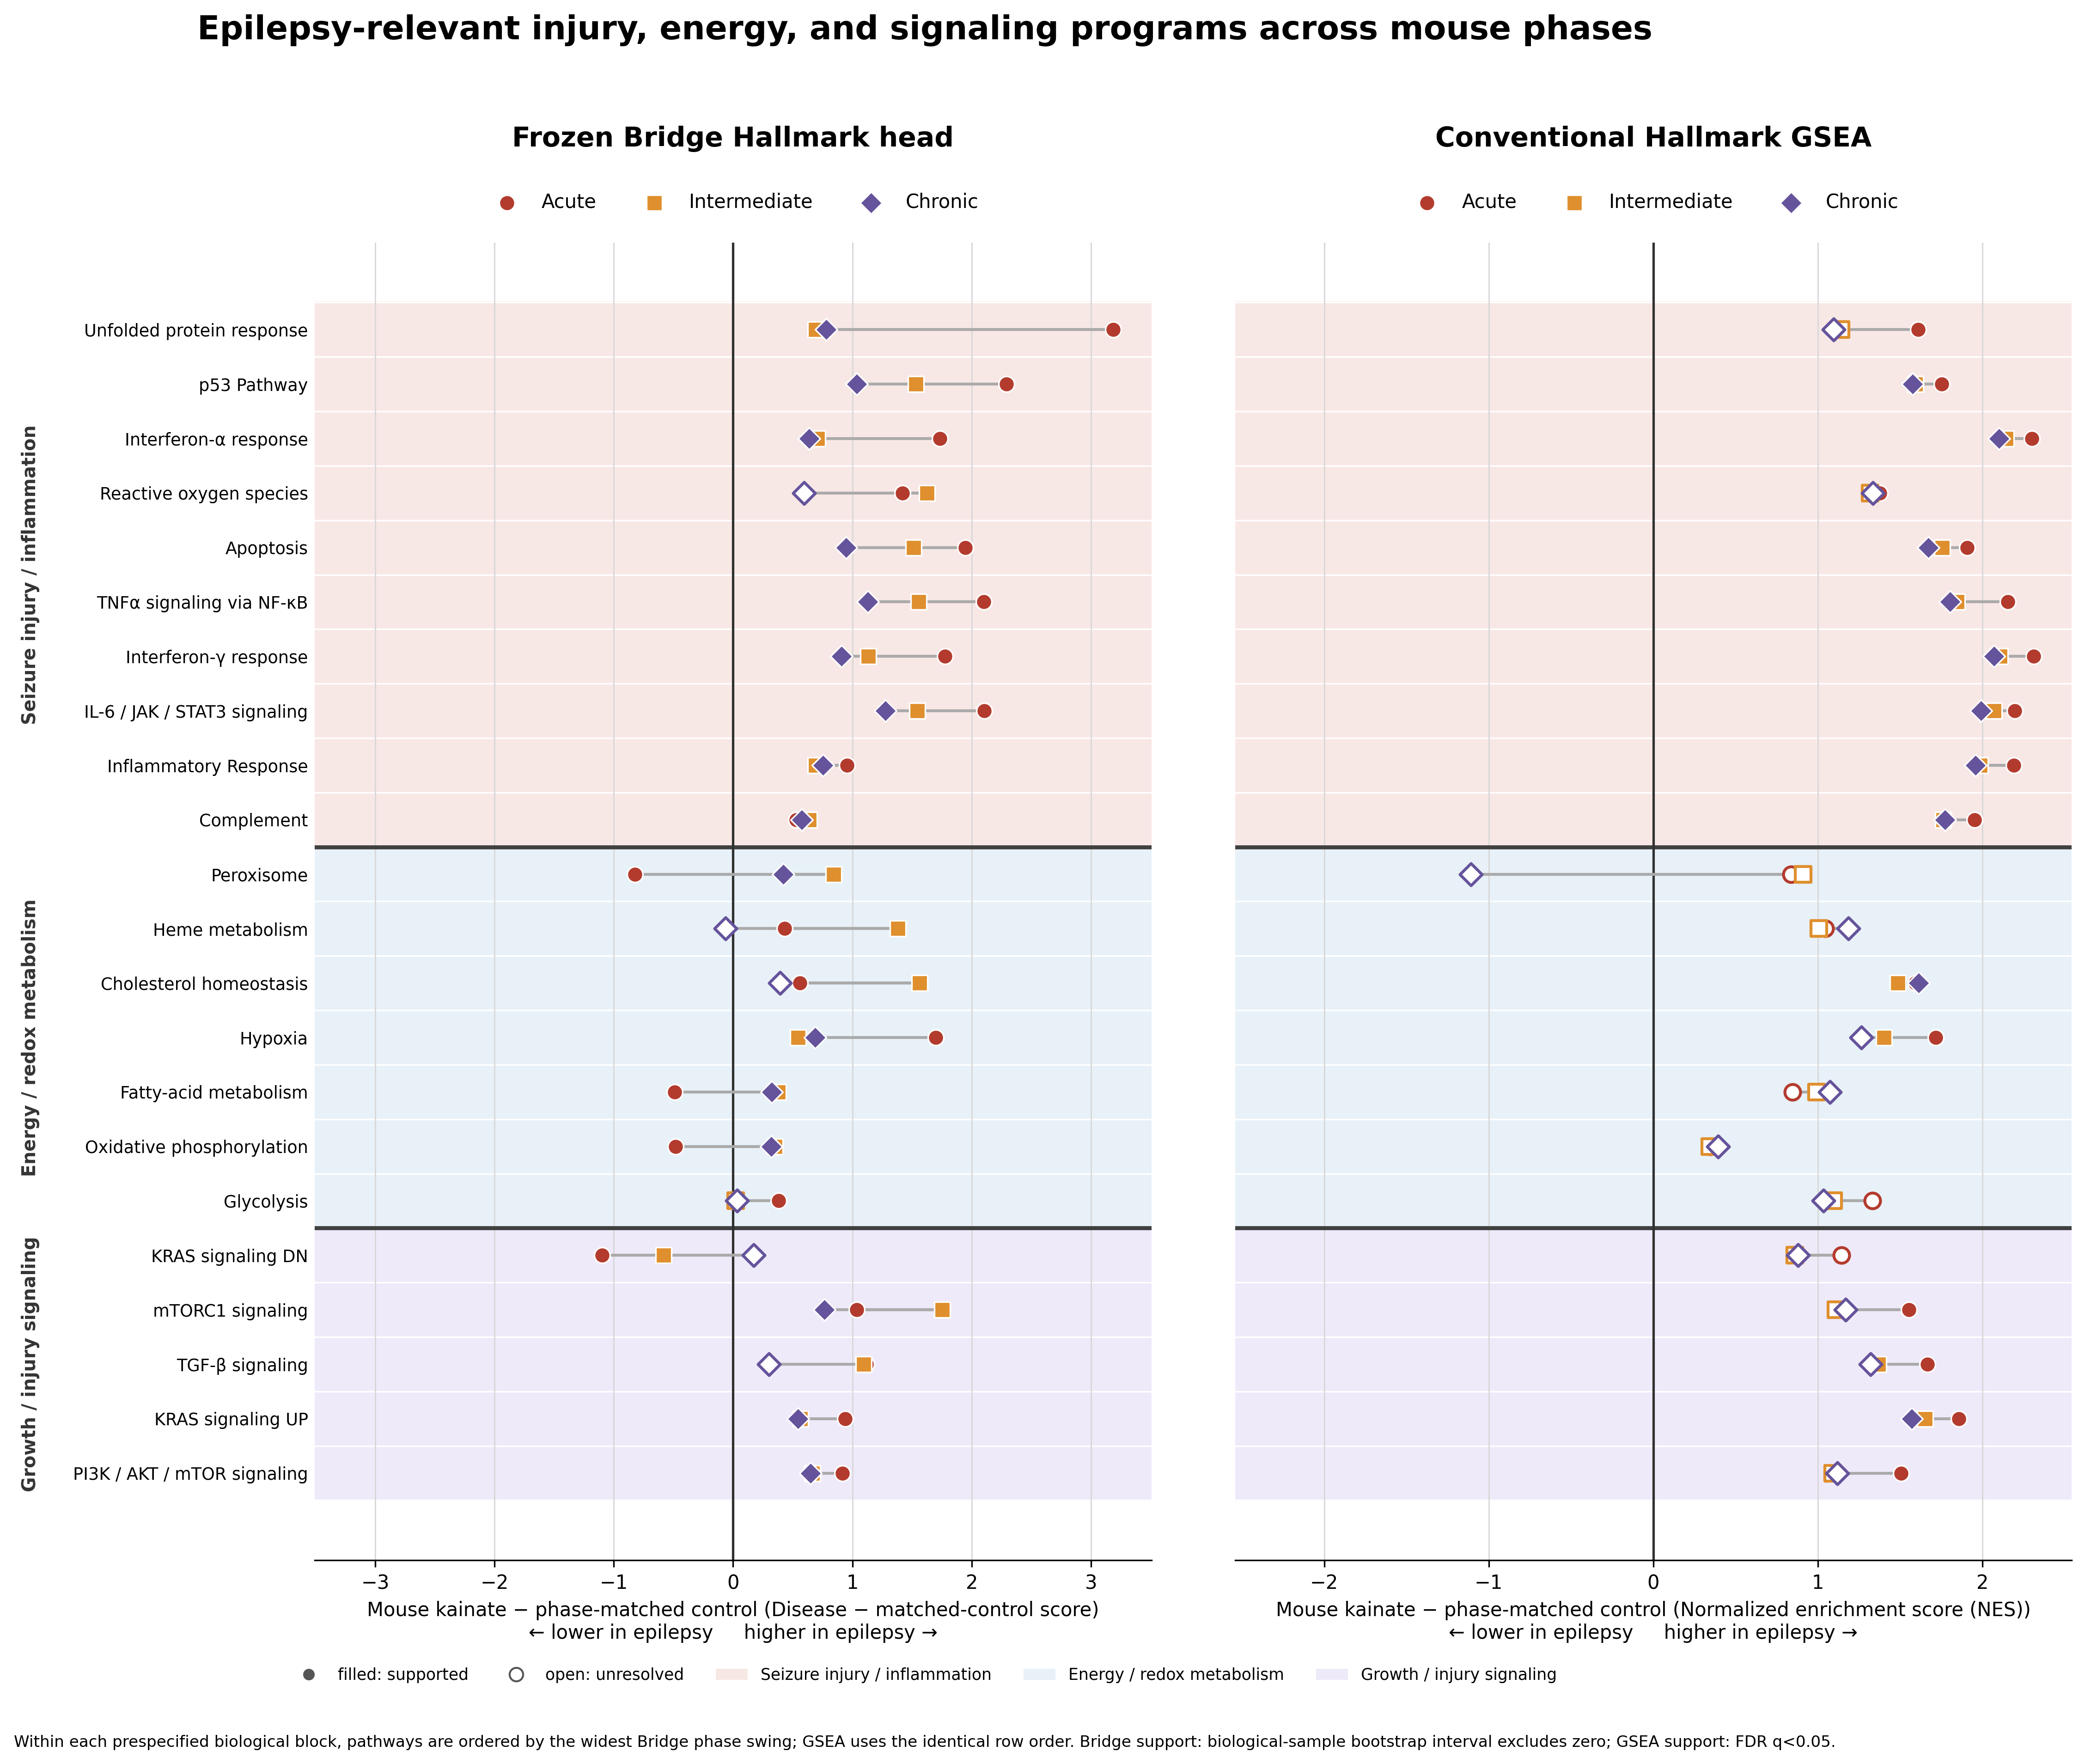

In [8]:
phase_table = pd.read_csv(CACHE / 'phase_resolved_hallmarks.csv')
assert len(phase_table) == 22
display(phase_table[['biological_group','hallmark','bridge_acute','bridge_intermediate',
                     'bridge_chronic','gsea_acute','gsea_intermediate','gsea_chronic']].round(3))
display(Image(filename=str(FIGURES / 'epilepsy_energy_three_phase_hallmark_states.png'), width=1100))

The head captured an acute injury/stress state involving unfolded-protein response, p53, interferons, apoptosis, TNF/NF-kB, IL-6/JAK/STAT3, and hypoxia, with several responses weakening by chronic disease. It also resolved dynamic energy/redox programs—acute decreases followed by intermediate/chronic increases in peroxisome, fatty-acid metabolism, and oxidative phosphorylation—and growth/injury programs including intermediate-peaking mTORC1 and attenuating TGF-beta. These phases represent different animals and are not longitudinal within-animal trajectories.

## Contextual organization and literature concordance

The final pre-mapped comparison with Kim et al. supported neuroinflammation through both contextual embeddings and acute IG, with TNF signaling receiving contextual support. The exact gliogenesis terms did not pass the original correction procedures. Bridge contextual networks were assessed against density-matched Pearson and Spearman coexpression; annotation co-membership measures functional organization, not physical interaction.

In [9]:
kim = pd.read_csv(CACHE / 'kim_validation_counts.csv')
network = pd.read_csv(CACHE / 'network_method_summary.csv')
functional = pd.read_csv(CACHE / 'network_functional_validation.csv')
display(kim)
display(network[['method','rewiring_cosine_min','rewiring_cosine_max',
                 'top1000_overlap_edges_total','top_rewiring_functional_tests_q05']].round(4))
bridge_top = functional[functional.edge_set.str.startswith('Bridge contextual L12') &
                        functional.edge_set.str.contains('top_rewiring_union')]
display(bridge_top[['edge_set','library','fold_enrichment','permutation_p','q']].round(4))

,category,themes
0,not testable,6
1,no evidence,4
2,opposite result,2
3,replicated,1
4,partial replication,1


,method,rewiring_cosine_min,rewiring_cosine_max,top1000_overlap_edges_total,top_rewiring_functional_tests_q05
0,Bridge contextual L12,-0.0009,0.0018,42,9
1,Pearson coexpression,0.0001,0.0005,1,0
2,Spearman coexpression,-0.0004,-0.0000,0,0


,edge_set,library,fold_enrichment,permutation_p,q
0,Bridge contextual L12|Acute|top_rewiring_union,GO,3.8071,0.002,0.0048
1,Bridge contextual L12|Acute|top_rewiring_union,KEGG,4.6598,0.002,0.0048
2,Bridge contextual L12|Acute|top_rewiring_union,Hallmark,14.2251,0.002,0.0048
6,Bridge contextual L12|Intermediate|top_rewirin...,GO,4.1043,0.002,0.0048
7,Bridge contextual L12|Intermediate|top_rewirin...,KEGG,4.7650,0.002,0.0048
8,Bridge contextual L12|Intermediate|top_rewirin...,Hallmark,14.1221,0.002,0.0048
12,Bridge contextual L12|Chronic|top_rewiring_union,GO,4.0566,0.002,0.0048
13,Bridge contextual L12|Chronic|top_rewiring_union,KEGG,4.9030,0.002,0.0048
14,Bridge contextual L12|Chronic|top_rewiring_union,Hallmark,14.6307,0.002,0.0048


Bridge-specific top rewiring edges were enriched approximately 3.8–4.2-fold for GO, 4.6–5.0-fold for KEGG, and 14.1–14.6-fold for Hallmark co-membership after removing matched coexpression top edges. Signed human–mouse rewiring cosines nevertheless remained near zero, placing the positive result at the level of functional organization rather than conserved disease rewiring.

## Limitations

- Human disease is confounded with tissue procurement: cases are surgical samples and controls are older post-mortem samples with higher mitochondrial contribution.
- The primary design contains one study per species, predominantly MTLE with hippocampal sclerosis, and six animals per mouse condition.
- Tissue acquisition and cellular composition differ between species; no fitted alignment was used to remove those differences.
- Hallmark sets overlap, and the human-trained head targets expression-derived pathway scores; Hallmark agreement is not independent biological validation.
- Contextual gene inference used 250 permutations, limiting gene-level null resolution. Network annotation enrichment is not PPI validation.
- IG measures model reliance rather than causality. Genes and pathways are not independent biological replicates.

## Conclusion

Frozen BridgeRNA representations produced suggestive acute-weighted cross-species geometry but did not pass the prespecified phenotype-label null. The clearest transferable result was higher-order functional organization: a human GTEx-trained Hallmark head recovered much of the mouse epilepsy pathway landscape zero-shot, identified coherent phase-resolved injury, metabolic, and growth-signaling states, and contextual networks recovered functional relationships beyond matched coexpression. Neuroinflammation was the strongest cross-species literature-concordant program. These findings support program-level transfer and organization while stopping short of conserved individual genes, conserved disease-network rewiring, or global human–mouse disease-state alignment.